# Projeto Final - Análise de Dados
## Grupo 3: Diagnóstico de Doenças Cardíacas

**Integrantes:** Luiz Henrique, Gustavo Tenório, Maycon C., Renan Valença

| Fase | Conteúdo | Responsável |
|---|---|---|
| 1 | Problema de negócio, carga do dataset e coluna alvo | Luiz |
| 2 | Análise exploratória (ausentes, outliers, duplicidade, redundância) | Luiz |
| 3 | Preparação de entrada/saída, aleatoriedade, divisão 70/15/15, balanceamento, numpy e normalização | Gustavo Tenório |
| 4 | Modelos (Regressão Linear/Logística, Naive Bayes, Random Forest), treino, `predict` e `predict_proba` | Maycon C. |
| 5 | Métricas, avaliação comparativa, escolha do melhor modelo e testes com novos dados | Renan Valença |

In [1]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils import resample
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             roc_auc_score, confusion_matrix, roc_curve,
                             ConfusionMatrixDisplay)

pd.set_option('display.max_columns', 50)
sns.set_theme(style='whitegrid')

---
## Fase 1: Estabelecimento do Problema de Negócio e Carga dos Dados
*(Responsável: Luiz)*

### 1.1 Problema de negócio
As doenças cardiovasculares estão entre as principais causas de morte no mundo. Em um pronto-atendimento,
o médico precisa decidir rapidamente quais pacientes devem seguir para exames mais caros e demorados
(cateterismo, angiotomografia). O objetivo deste projeto é construir um modelo de *Machine Learning*
que, a partir de dados clínicos simples coletados na triagem, **estime o risco de o paciente ter doença
arterial coronariana**, apoiando (e não substituindo) a decisão médica.

Como é um problema de saúde, **o erro mais grave é o falso negativo** (dizer que um paciente doente é
saudável e mandá-lo para casa). Por isso, além da acurácia, daremos atenção especial ao **recall
(sensibilidade)** e ao **ROC AUC**, sem esquecer da **especificidade** (evitar exames desnecessários).

### 1.2 Dataset
* **Fonte:** Kaggle – *Heart Disease Dataset* (johnsmith88), que combina as bases de Cleveland,
  Hungria, Suíça e Long Beach V do repositório UCI.
* **Registros:** 1025 linhas, 13 variáveis de entrada e 1 coluna alvo.

| Coluna | Descrição |
|---|---|
| age | Idade (anos) |
| sex | Sexo (1 = masculino, 0 = feminino) |
| cp | Tipo de dor no peito (0 a 3) |
| trestbps | Pressão arterial em repouso (mm Hg) |
| chol | Colesterol sérico (mg/dl) |
| fbs | Glicemia em jejum > 120 mg/dl (1 = sim) |
| restecg | Resultado do eletrocardiograma em repouso (0 a 2) |
| thalach | Frequência cardíaca máxima atingida |
| exang | Angina induzida por exercício (1 = sim) |
| oldpeak | Depressão do segmento ST induzida por exercício |
| slope | Inclinação do segmento ST no pico do exercício (0 a 2) |
| ca | Nº de vasos principais coloridos por fluoroscopia (0 a 3) |
| thal | Talassemia (1 = normal, 2 = defeito fixo, 3 = defeito reversível) |
| **target** | **0 = Saudável, 1 = Com doença cardíaca** |

In [2]:
# Carga do dataset. Se o arquivo heart.csv não estiver na mesma pasta do notebook,
# baixa uma cópia pública do mesmo dataset do Kaggle.
import os
ARQUIVO = 'heart.csv'
URL_BACKUP = 'https://raw.githubusercontent.com/DataThinkers/Datasets/main/DS/heart.csv'

df_original = pd.read_csv(ARQUIVO if os.path.exists(ARQUIVO) else URL_BACKUP)
print('Formato do dataset:', df_original.shape)
df_original.head()

Formato do dataset: (1025, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [3]:
df_original.info()

<class 'pandas.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [4]:
df_original.describe().T

,count,mean,std,min,25%,50%,75%,max
age,1025.0,54.434146,9.072290,29.0,48.0,56.0,61.0,77.0
sex,1025.0,0.695610,0.460373,0.0,0.0,1.0,1.0,1.0
cp,1025.0,0.942439,1.029641,0.0,0.0,1.0,2.0,3.0
trestbps,1025.0,131.611707,17.516718,94.0,120.0,130.0,140.0,200.0
chol,1025.0,246.000000,51.592510,126.0,211.0,240.0,275.0,564.0
fbs,1025.0,0.149268,0.356527,0.0,0.0,0.0,0.0,1.0
restecg,1025.0,0.529756,0.527878,0.0,0.0,1.0,1.0,2.0
thalach,1025.0,149.114146,23.005724,71.0,132.0,152.0,166.0,202.0
exang,1025.0,0.336585,0.472772,0.0,0.0,0.0,1.0,1.0
oldpeak,1025.0,1.071512,1.175053,0.0,0.0,0.8,1.8,6.2


### 1.3 Definição da coluna alvo (target)
A coluna alvo é **`target`** (0 = Saudável, 1 = Com doença cardíaca). Trata-se de um problema de
**classificação binária**. *(Na seção 2.3 verificamos que, no arquivo do Kaggle, os rótulos estão
invertidos e fazemos a correção.)*

target
0    499
1    526
Name: count, dtype: int64

Proporção (%):
target
0    48.68
1    51.32
Name: proportion, dtype: float64


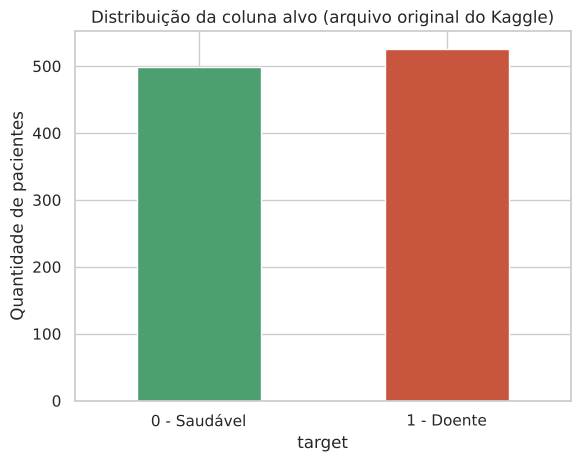

In [5]:
TARGET = 'target'

contagem = df_original[TARGET].value_counts().sort_index()
print(contagem)
print('\nProporção (%):')
print((df_original[TARGET].value_counts(normalize=True).sort_index() * 100).round(2))

ax = contagem.plot(kind='bar', color=['#4C9F70', '#C8553D'])
ax.set_xticklabels(['0 - Saudável', '1 - Doente'], rotation=0)
ax.set_title('Distribuição da coluna alvo (arquivo original do Kaggle)')
ax.set_ylabel('Quantidade de pacientes')
plt.show()

---
## Fase 2: Análise Exploratória de Dados (EDA)
*(Responsável: Luiz)*

Trabalharemos em uma cópia (`df`) para preservar o dataset original.

In [6]:
df = df_original.copy()

### 2.1 Dados ausentes

In [7]:
ausentes = df.isnull().sum()
print('Valores nulos por coluna:')
print(ausentes)
print('\nTotal de valores nulos:', ausentes.sum())

Valores nulos por coluna:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Total de valores nulos: 0


Não há valores nulos explícitos (`NaN`). Porém, a documentação original da UCI define que:
* `ca` (nº de vasos) vai de **0 a 3** → o valor **4** é inválido;
* `thal` assume **1, 2 ou 3** → o valor **0** é inválido.

Esses códigos são, na prática, **dados ausentes disfarçados**. Vamos convertê-los em `NaN` e
imputá-los pela **moda** (valor mais frequente), que é a escolha adequada para variáveis categóricas.

In [8]:
print('Registros com ca = 4  :', (df['ca'] == 4).sum())
print('Registros com thal = 0:', (df['thal'] == 0).sum())

df['ca'] = df['ca'].replace(4, np.nan)
df['thal'] = df['thal'].replace(0, np.nan)
print('\nAusentes após marcar códigos inválidos:')
print(df[['ca', 'thal']].isnull().sum())

Registros com ca = 4  : 18
Registros com thal = 0: 7

Ausentes após marcar códigos inválidos:
ca      18
thal     7
dtype: int64


### 2.2 Duplicidade de linhas
Este dataset é conhecido por ter muitas linhas repetidas. Se as duplicatas forem mantidas, **o mesmo
paciente pode cair no treino e no teste ao mesmo tempo**, fazendo o modelo "decorar" a resposta e
gerando métricas infladas (vazamento de dados / *data leakage*). Por isso elas serão removidas.

In [9]:
n_dup = df.duplicated().sum()
print(f'Linhas duplicadas: {n_dup} de {len(df)} ({n_dup / len(df):.1%})')

df = df.drop_duplicates().reset_index(drop=True)
print('Formato após remover duplicatas:', df.shape)

Linhas duplicadas: 723 de 1025 (70.5%)
Formato após remover duplicatas: (302, 14)


In [10]:
# Imputação dos ausentes pela moda (feita depois de remover duplicatas)
for col in ['ca', 'thal']:
    moda = df[col].mode()[0]
    df[col] = df[col].fillna(moda).astype(int)
    print(f'{col}: ausentes preenchidos com a moda = {moda:.0f}')

print('\nTotal de nulos restantes:', df.isnull().sum().sum())
print('\nDistribuição do target após limpeza:')
print(df[TARGET].value_counts().sort_index())

ca: ausentes preenchidos com a moda = 0
thal: ausentes preenchidos com a moda = 2

Total de nulos restantes: 0

Distribuição do target após limpeza:
target
0    138
1    164
Name: count, dtype: int64


### 2.3 Verificação da coerência da coluna alvo
Antes de modelar, conferimos se o `target` faz sentido clínico. Pela literatura médica, pacientes
**doentes** tendem a ser mais velhos e do sexo masculino, a ter angina induzida por exercício (`exang`),
maior depressão ST (`oldpeak`), mais vasos obstruídos (`ca`) e **menor** frequência cardíaca máxima
(`thalach`).

In [11]:
perfil = df.groupby(TARGET)[['age', 'sex', 'exang', 'oldpeak', 'ca', 'thalach']].mean().round(2)
print('Média de cada variável por valor do target (dataset do Kaggle):')
print(perfil)
print('\n% de target = 1 entre quem TEM angina no exercício (exang = 1):',
      f"{df.loc[df['exang'] == 1, TARGET].mean():.0%}")
print('% de target = 1 entre quem NÃO tem angina no exercício (exang = 0):',
      f"{df.loc[df['exang'] == 0, TARGET].mean():.0%}")

Média de cada variável por valor do target (dataset do Kaggle):
          age   sex  exang  oldpeak    ca  thalach
target                                            
0       56.60  0.83   0.55     1.59  1.14   139.10
1       52.59  0.56   0.14     0.59  0.27   158.38

% de target = 1 entre quem TEM angina no exercício (exang = 1): 23%
% de target = 1 entre quem NÃO tem angina no exercício (exang = 0): 69%


O resultado é o **oposto** do esperado: no arquivo do Kaggle, o grupo `target = 1` é mais jovem, tem
menos angina, menor `oldpeak`, menos vasos obstruídos e maior frequência máxima, ou seja, é o perfil
**saudável**. Além disso, após remover as duplicatas sobram 164 registros com `target = 1` e 138 com
`target = 0`, enquanto a base original de Cleveland (UCI) tem 164 pacientes **sem** doença e 139
**com** doença. Esse rótulo invertido é um problema conhecido da versão johnsmith88 do Kaggle.

Para que o modelo siga a definição do projeto (**0 = Saudável, 1 = Com doença cardíaca**), invertemos
a coluna alvo: `target = 1 − target`.

In [12]:
df[TARGET] = 1 - df[TARGET]

print('Perfil após a correção (1 = com doença):')
print(df.groupby(TARGET)[['age', 'sex', 'exang', 'oldpeak', 'ca', 'thalach']].mean().round(2))
print('\nDistribuição corrigida do target:')
print(df[TARGET].value_counts().sort_index().rename({0: '0 - Saudável', 1: '1 - Doente'}))

Perfil após a correção (1 = com doença):
          age   sex  exang  oldpeak    ca  thalach
target                                            
0       52.59  0.56   0.14     0.59  0.27   158.38
1       56.60  0.83   0.55     1.59  1.14   139.10

Distribuição corrigida do target:
target
0 - Saudável    164
1 - Doente      138
Name: count, dtype: int64


### 2.4 Duplicidade de colunas e colunas redundantes
* **Colunas duplicadas:** colunas com exatamente os mesmos valores.
* **Colunas redundantes:** colunas fortemente correlacionadas entre si (|r| > 0,9), que carregariam a
  mesma informação; também verificamos colunas constantes (um único valor).

In [13]:
colunas_duplicadas = df.columns[df.T.duplicated()].tolist()
print('Colunas duplicadas:', colunas_duplicadas if colunas_duplicadas else 'nenhuma')

colunas_constantes = [c for c in df.columns if df[c].nunique() <= 1]
print('Colunas constantes:', colunas_constantes if colunas_constantes else 'nenhuma')

corr = df.corr()
pares = []
for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        if abs(corr.iloc[i, j]) > 0.9:
            pares.append((corr.columns[i], corr.columns[j], round(corr.iloc[i, j], 3)))
print('Pares de colunas com |correlação| > 0.9:', pares if pares else 'nenhum')

Colunas duplicadas: nenhuma
Colunas constantes: nenhuma


Pares de colunas com |correlação| > 0.9: nenhum


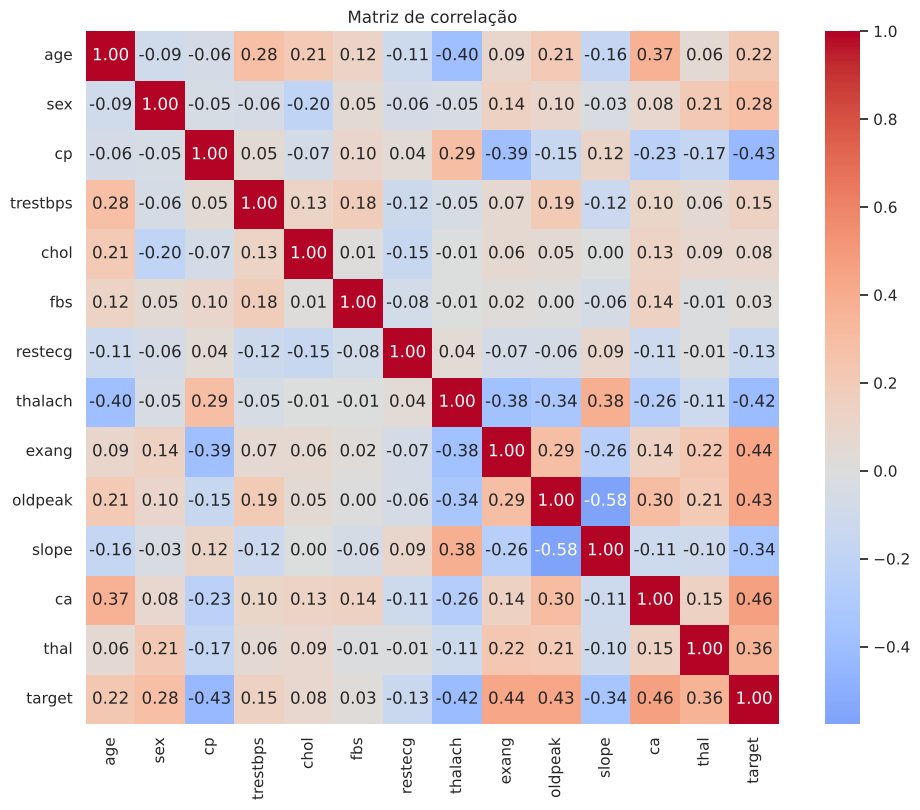

Correlação de cada variável com o target:
ca          0.464
exang       0.436
oldpeak     0.429
thal        0.362
sex         0.284
age         0.221
trestbps    0.146
chol        0.081
fbs         0.027
restecg    -0.135
slope      -0.344
thalach    -0.420
cp         -0.432
Name: target, dtype: float64


In [14]:
plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Matriz de correlação')
plt.show()

print('Correlação de cada variável com o target:')
print(corr[TARGET].drop(TARGET).sort_values(ascending=False).round(3))

Não existem colunas duplicadas, constantes ou com correlação acima de 0,9. A maior correlação entre
variáveis de entrada é moderada (ex.: `slope` × `oldpeak`), então **todas as 13 variáveis são mantidas**.
Com o target corrigido, as associações ficam coerentes com a medicina: `ca`, `exang`, `oldpeak` e
`thal` aumentam o risco (correlação positiva), enquanto `cp`, `thalach` e `slope` aparecem com
correlação negativa.

### 2.5 Dados outliers

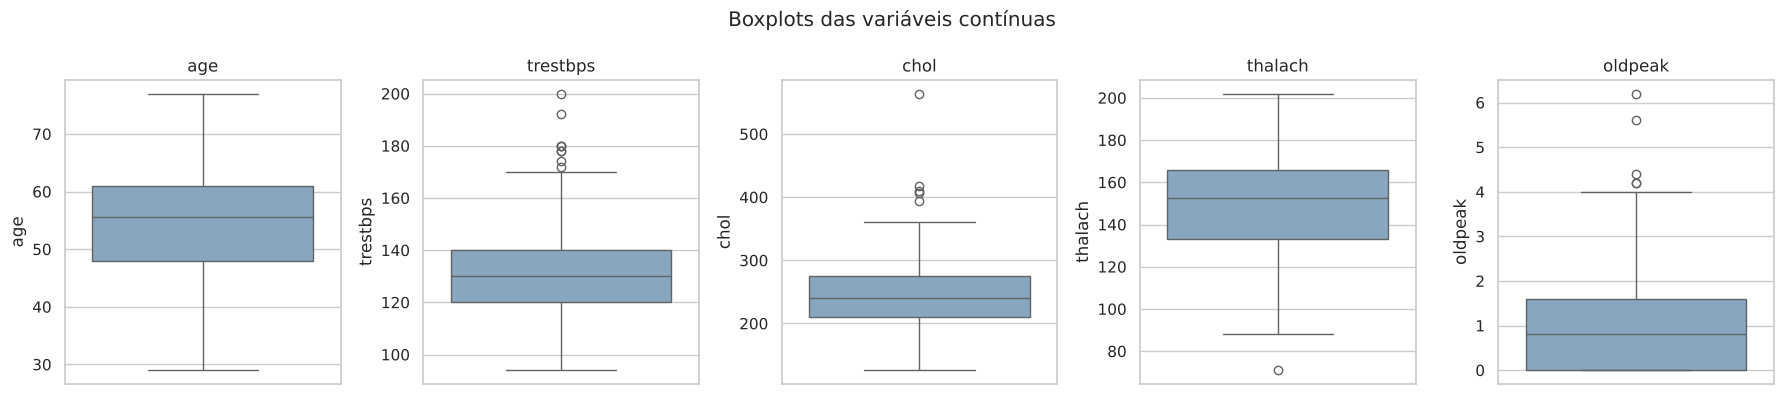

,coluna,outliers,limite_inferior,limite_superior,min,max
0,age,0,28.50,80.50,29.0,77.0
1,trestbps,9,90.00,170.00,94.0,200.0
2,chol,5,115.38,370.38,126.0,564.0
3,thalach,1,84.12,215.12,71.0,202.0
4,oldpeak,5,-2.40,4.00,0.0,6.2


In [15]:
continuas = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

fig, axes = plt.subplots(1, len(continuas), figsize=(18, 4))
for ax, col in zip(axes, continuas):
    sns.boxplot(y=df[col], ax=ax, color='#7FA7C9')
    ax.set_title(col)
plt.suptitle('Boxplots das variáveis contínuas')
plt.tight_layout()
plt.show()

def outliers_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((serie < lim_inf) | (serie > lim_sup)).sum(), lim_inf, lim_sup

resumo = []
for col in continuas:
    n, li, ls = outliers_iqr(df[col])
    resumo.append({'coluna': col, 'outliers': n, 'limite_inferior': round(li, 2),
                   'limite_superior': round(ls, 2), 'min': df[col].min(), 'max': df[col].max()})
pd.DataFrame(resumo)

Pelo critério do IQR (1,5 × intervalo interquartil) aparecem alguns outliers em `trestbps`, `chol`,
`thalach` e `oldpeak`. Todos são **valores clinicamente possíveis** (ex.: colesterol de 564 mg/dl ou
pressão de 200 mm Hg existem em pacientes reais) e podem justamente indicar pacientes de risco.
Removê-los descartaria informação relevante em um dataset já pequeno. Por isso, **os outliers são
mantidos**, e a normalização (Fase 3) e o Random Forest (robusto a outliers) reduzem seu impacto.

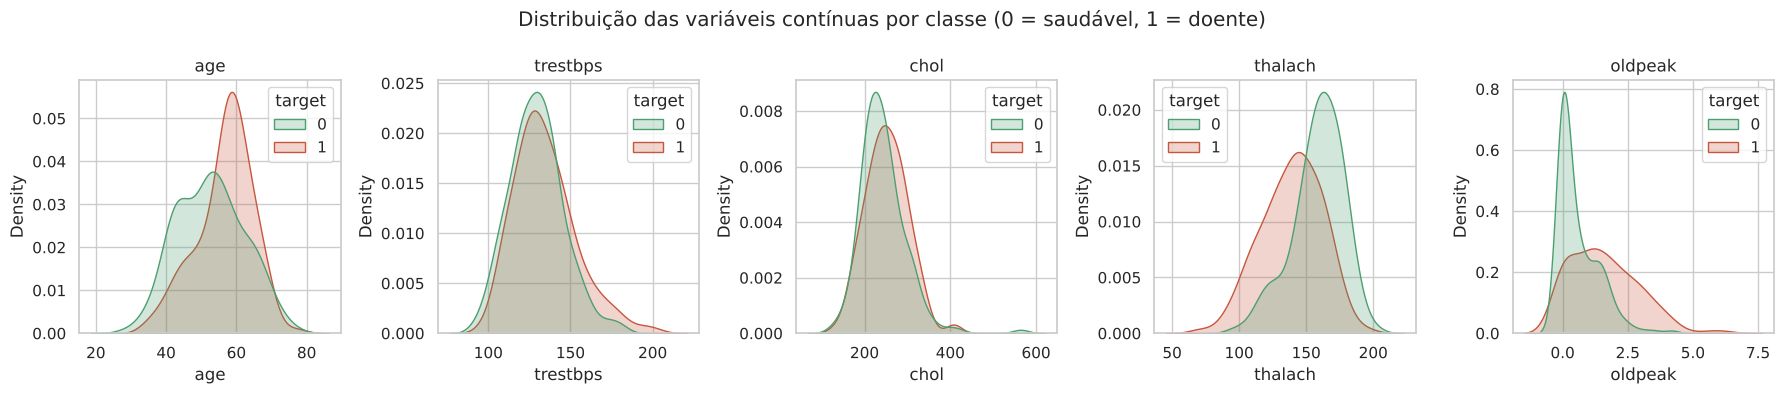

In [16]:
fig, axes = plt.subplots(1, len(continuas), figsize=(18, 4))
for ax, col in zip(axes, continuas):
    sns.kdeplot(data=df, x=col, hue=TARGET, fill=True, common_norm=False, ax=ax, palette=['#4C9F70', '#C8553D'])
    ax.set_title(col)
plt.suptitle('Distribuição das variáveis contínuas por classe (0 = saudável, 1 = doente)')
plt.tight_layout()
plt.show()

---
## Fase 3: Preparação, Aleatoriedade, Divisão, Balanceamento, NumPy e Normalização
*(Responsável: Gustavo Tenório)*

A ordem das etapas foi pensada para **evitar vazamento de informação** do conjunto de teste para o
treinamento: primeiro dividimos os dados e só depois balanceamos e normalizamos, usando **apenas o
conjunto de treino** como referência.

### 3.1 Preparação dos dados de entrada (X) e de saída (y)
As variáveis `cp`, `restecg`, `slope` e `thal` são **categóricas nominais** (os números são apenas
códigos, não quantidades). Elas são transformadas com *one-hot encoding* (`pd.get_dummies`, com
`drop_first=True` para evitar colunas redundantes). As demais já são numéricas ou binárias.

In [17]:
CATEGORICAS = ['cp', 'restecg', 'slope', 'thal']

X_df = pd.get_dummies(df.drop(columns=[TARGET]), columns=CATEGORICAS, drop_first=True, dtype=int)
y_sr = df[TARGET]

COLUNAS_MODELO = X_df.columns.tolist()   # guardado para preparar novos dados na Fase 5
print('Entrada X:', X_df.shape, '| Saída y:', y_sr.shape)
print('Colunas de entrada:', COLUNAS_MODELO)
X_df.head()

Entrada X: (302, 18) | Saída y: (302,)
Colunas de entrada: ['age', 'sex', 'trestbps', 'chol', 'fbs', 'thalach', 'exang', 'oldpeak', 'ca', 'cp_1', 'cp_2', 'cp_3', 'restecg_1', 'restecg_2', 'slope_1', 'slope_2', 'thal_2', 'thal_3']


,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,ca,cp_1,cp_2,cp_3,restecg_1,restecg_2,slope_1,slope_2,thal_2,thal_3
0,52,1,125,212,0,168,0,1.0,2,0,0,0,1,0,0,1,0,1
1,53,1,140,203,1,155,1,3.1,0,0,0,0,0,0,0,0,0,1
2,70,1,145,174,0,125,1,2.6,0,0,0,0,1,0,0,0,0,1
3,61,1,148,203,0,161,0,0.0,1,0,0,0,1,0,0,1,0,1
4,62,0,138,294,1,106,0,1.9,3,0,0,0,1,0,1,0,1,0


### 3.2 Preparação da aleatoriedade
Fixamos uma semente (`SEED`) para que embaralhamento, divisão, balanceamento e Random Forest
gerem sempre o mesmo resultado (**reprodutibilidade**). Em seguida, embaralhamos as linhas.

In [18]:
SEED = 42
np.random.seed(SEED)

indices = np.random.permutation(len(X_df))
X_df = X_df.iloc[indices].reset_index(drop=True)
y_sr = y_sr.iloc[indices].reset_index(drop=True)
print('Primeiros índices após embaralhar:', indices[:10])

Primeiros índices após embaralhar: [179 228 111 246  60   9 119 223 267  33]


### 3.3 Divisão em treino / validação / teste (70 / 15 / 15)
A divisão é feita em duas etapas com `train_test_split`, usando `stratify` para manter a mesma
proporção de doentes e saudáveis em cada parte:
1. 70% treino e 30% restante;
2. o restante é dividido ao meio: 15% validação e 15% teste.

* **Treino:** ajusta os modelos.
* **Validação:** compara os modelos e escolhe o melhor.
* **Teste:** avaliação final, com dados nunca vistos.

In [19]:
X_treino_df, X_temp_df, y_treino_sr, y_temp_sr = train_test_split(
    X_df, y_sr, test_size=0.30, random_state=SEED, stratify=y_sr)

X_val_df, X_teste_df, y_val_sr, y_teste_sr = train_test_split(
    X_temp_df, y_temp_sr, test_size=0.50, random_state=SEED, stratify=y_temp_sr)

total = len(X_df)
for nome, parte in [('Treino', X_treino_df), ('Validação', X_val_df), ('Teste', X_teste_df)]:
    print(f'{nome:10s}: {len(parte):4d} linhas ({len(parte) / total:.1%})')

print('\nProporção de doentes (classe 1) em cada parte:')
for nome, alvo in [('Treino', y_treino_sr), ('Validação', y_val_sr), ('Teste', y_teste_sr)]:
    print(f'{nome:10s}: {alvo.mean():.1%}')

Treino    :  211 linhas (69.9%)
Validação :   45 linhas (14.9%)
Teste     :   46 linhas (15.2%)

Proporção de doentes (classe 1) em cada parte:
Treino    : 45.5%
Validação : 46.7%
Teste     : 45.7%


### 3.4 Balanceamento dos dados
O balanceamento é aplicado **somente no treino** (validação e teste precisam refletir a realidade).
Usamos **oversampling aleatório**: sorteamos com reposição exemplos da classe minoritária até ela ter
o mesmo tamanho da majoritária (`sklearn.utils.resample`).

Antes do balanceamento:
target
0    115
1     96
Name: count, dtype: int64

Depois do balanceamento:
target
0    115
1    115
Name: count, dtype: int64


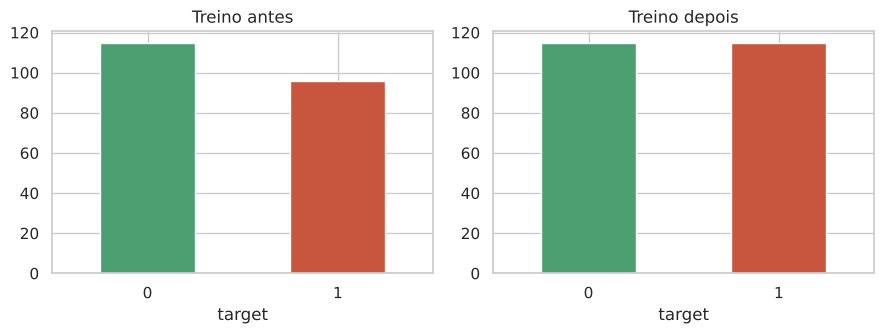

In [20]:
treino = pd.concat([X_treino_df, y_treino_sr], axis=1)
print('Antes do balanceamento:')
print(treino[TARGET].value_counts().sort_index())

classe_maj = treino[TARGET].value_counts().idxmax()
classe_min = treino[TARGET].value_counts().idxmin()
df_maj = treino[treino[TARGET] == classe_maj]
df_min = treino[treino[TARGET] == classe_min]

df_min_up = resample(df_min, replace=True, n_samples=len(df_maj), random_state=SEED)
treino_bal = pd.concat([df_maj, df_min_up]).sample(frac=1, random_state=SEED).reset_index(drop=True)

print('\nDepois do balanceamento:')
print(treino_bal[TARGET].value_counts().sort_index())

X_treino_df = treino_bal.drop(columns=[TARGET])
y_treino_sr = treino_bal[TARGET]

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
treino[TARGET].value_counts().sort_index().plot(kind='bar', ax=axes[0], color=['#4C9F70', '#C8553D'], title='Treino antes')
y_treino_sr.value_counts().sort_index().plot(kind='bar', ax=axes[1], color=['#4C9F70', '#C8553D'], title='Treino depois')
for ax in axes:
    ax.set_xticklabels(['0', '1'], rotation=0)
plt.tight_layout()
plt.show()

### 3.5 Conversão para matrizes NumPy
Os modelos do scikit-learn trabalham internamente com arrays NumPy; fazemos a conversão explícita.

In [21]:
X_treino = X_treino_df.to_numpy(dtype=float)
X_val    = X_val_df.to_numpy(dtype=float)
X_teste  = X_teste_df.to_numpy(dtype=float)

y_treino = y_treino_sr.to_numpy()
y_val    = y_val_sr.to_numpy()
y_teste  = y_teste_sr.to_numpy()

for nome, m in [('X_treino', X_treino), ('X_val', X_val), ('X_teste', X_teste),
                ('y_treino', y_treino), ('y_val', y_val), ('y_teste', y_teste)]:
    print(f'{nome:9s} -> {type(m).__name__}, shape = {m.shape}')

X_treino  -> ndarray, shape = (230, 18)
X_val     -> ndarray, shape = (45, 18)
X_teste   -> ndarray, shape = (46, 18)
y_treino  -> ndarray, shape = (230,)
y_val     -> ndarray, shape = (45,)
y_teste   -> ndarray, shape = (46,)


### 3.6 Normalização dos dados
Usamos o **`StandardScaler`** (padronização *z-score*: `z = (x − média) / desvio padrão`), deixando
cada variável com média 0 e desvio 1. Isso é importante para a Regressão Logística e o Naive Bayes,
que são sensíveis à escala das variáveis. O scaler é **ajustado (`fit`) apenas no treino** e depois
aplicado (`transform`) na validação e no teste.

In [22]:
scaler = StandardScaler()
X_treino = scaler.fit_transform(X_treino)
X_val    = scaler.transform(X_val)
X_teste  = scaler.transform(X_teste)

print('Médias do treino após normalizar (≈0):', X_treino.mean(axis=0).round(2)[:6], '...')
print('Desvios do treino após normalizar (≈1):', X_treino.std(axis=0).round(2)[:6], '...')

Médias do treino após normalizar (≈0): [-0.  0.  0. -0. -0. -0.] ...
Desvios do treino após normalizar (≈1): [1. 1. 1. 1. 1. 1.] ...


---
## Fase 4: Construção dos Modelos, Treinamento e Previsões
*(Responsável: Maycon C.)*

Três modelos de classificação:

1. **Regressão Linear para classificação → Regressão Logística.** A `LinearRegression` comum prevê
   valores contínuos (pode dar −0,3 ou 1,4) e **não possui `predict_proba`**, exigido pelo projeto.
   A Regressão Logística é o modelo linear para classificação: calcula a mesma combinação linear
   `w·x + b` e a passa pela função sigmoide, gerando uma probabilidade entre 0 e 1.
   (Ao final da fase mostramos a `LinearRegression` pura apenas como comparação.)
2. **Naive Bayes Gaussiano:** aplica o Teorema de Bayes assumindo independência entre as variáveis e
   distribuição normal em cada uma.
3. **Random Forest:** conjunto de várias árvores de decisão treinadas em amostras aleatórias; a
   classe final é decidida por votação.

**Ajuste do Naive Bayes.** Com o valor padrão (`var_smoothing = 1e-9`), as variáveis binárias criadas
pelo one-hot (algumas com pouquíssimos casos) geram variâncias muito pequenas e probabilidades
extremas, e o modelo quase não detecta doentes. O parâmetro `var_smoothing` soma uma fração da maior
variância a todas as variâncias, suavizando esse efeito. Escolhemos o valor usando o **conjunto de
validação** (maior ROC AUC). O teste não é usado nessa escolha.

In [23]:
busca_nb = []
for vs in [1e-9, 1e-3, 1e-2, 1e-1, 0.3, 1.0]:
    nb_tmp = GaussianNB(var_smoothing=vs).fit(X_treino, y_treino)
    busca_nb.append({'var_smoothing': vs,
                     'Recall (val)': recall_score(y_val, nb_tmp.predict(X_val)),
                     'ROC AUC (val)': roc_auc_score(y_val, nb_tmp.predict_proba(X_val)[:, 1])})
busca_nb = pd.DataFrame(busca_nb)
MELHOR_VS = busca_nb.loc[busca_nb['ROC AUC (val)'].idxmax(), 'var_smoothing']
print('var_smoothing escolhido:', MELHOR_VS)
busca_nb.round(4)

var_smoothing escolhido: 1.0


,var_smoothing,Recall (val),ROC AUC (val)
0,0.000,0.2857,0.7946
1,0.001,0.5238,0.7966
2,0.010,0.6667,0.7966
3,0.100,0.7143,0.8006
4,0.300,0.7619,0.8026
5,1.000,0.7619,0.8105


In [24]:
modelos = {
    'Regressão Linear (Logística)': LogisticRegression(max_iter=1000, random_state=SEED),
    'Naive Bayes': GaussianNB(var_smoothing=MELHOR_VS),
    'Random Forest': RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=2,
                                            random_state=SEED, n_jobs=-1),
}

for nome, modelo in modelos.items():
    modelo.fit(X_treino, y_treino)
    print(f'{nome} treinado.')

Regressão Linear (Logística) treinado.
Naive Bayes treinado.


Random Forest treinado.


### 4.1 Cálculo das previsões com `predict` e `predict_proba`
* `predict` devolve a **classe** prevista (0 ou 1), usando limiar de 0,5.
* `predict_proba` devolve a **probabilidade** de cada classe; a coluna `[:, 1]` é a probabilidade de
  o paciente ter doença cardíaca.

In [25]:
previsoes = {}   # previsões no conjunto de VALIDAÇÃO
for nome, modelo in modelos.items():
    y_pred  = modelo.predict(X_val)
    y_proba = modelo.predict_proba(X_val)[:, 1]
    previsoes[nome] = {'y_pred': y_pred, 'y_proba': y_proba}

exemplo = pd.DataFrame({'real': y_val[:10]})
for nome, p in previsoes.items():
    exemplo[f'{nome} | predict'] = p['y_pred'][:10]
    exemplo[f'{nome} | proba'] = p['y_proba'][:10].round(3)
exemplo

,real,Regressão Linear (Logística) | predict,Regressão Linear (Logística) | proba,Naive Bayes | predict,Naive Bayes | proba,Random Forest | predict,Random Forest | proba
0,0,0,0.005,0,0.011,0,0.031
1,0,0,0.002,0,0.009,0,0.053
2,1,1,0.965,1,0.991,1,0.836
3,0,0,0.055,0,0.005,0,0.083
4,0,0,0.121,0,0.033,0,0.152
5,1,1,0.978,1,1.000,1,0.580
6,1,0,0.147,0,0.117,0,0.193
7,1,0,0.323,1,0.827,1,0.670
8,0,0,0.309,0,0.078,0,0.289
9,0,0,0.012,0,0.040,0,0.124


In [26]:
# Comparação: LinearRegression "pura" usada como classificador (limiar 0,5).
# Não possui predict_proba; seus valores nem sempre ficam entre 0 e 1.
lin = LinearRegression().fit(X_treino, y_treino)
saida_lin = lin.predict(X_val)
print('Faixa das saídas da LinearRegression:', saida_lin.min().round(2), 'a', saida_lin.max().round(2))
print('Tem predict_proba?', hasattr(lin, 'predict_proba'))
print('Acurácia com limiar 0,5:', round(accuracy_score(y_val, (saida_lin >= 0.5).astype(int)), 4))

Faixa das saídas da LinearRegression: -0.33 a 1.25
Tem predict_proba? False
Acurácia com limiar 0,5: 0.7556


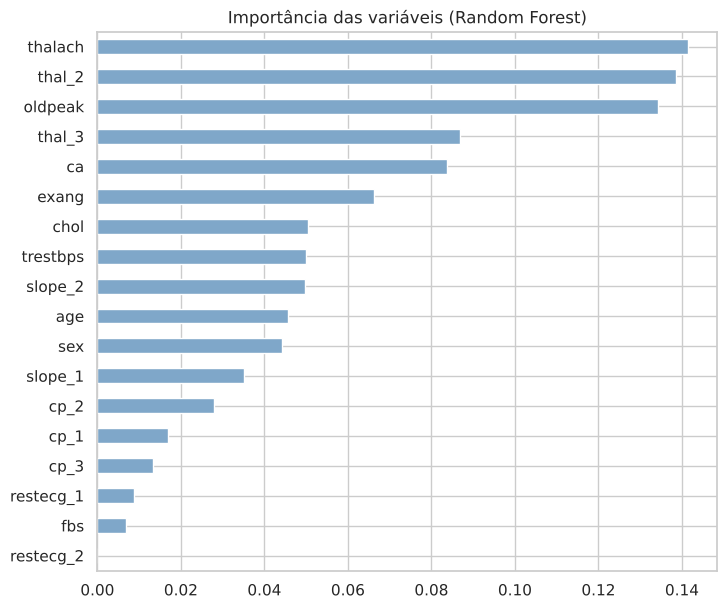

In [27]:
# Importância das variáveis segundo o Random Forest
importancias = pd.Series(modelos['Random Forest'].feature_importances_, index=COLUNAS_MODELO).sort_values()
importancias.plot(kind='barh', figsize=(8, 7), color='#7FA7C9')
plt.title('Importância das variáveis (Random Forest)')
plt.show()

---
## Fase 5: Métricas, Avaliação dos Modelos e Testes com Novos Dados
*(Responsável: Renan Valença)*

### 5.1 Construção do cálculo das métricas
A partir da matriz de confusão (VP = verdadeiros positivos, VN = verdadeiros negativos,
FP = falsos positivos, FN = falsos negativos):

| Métrica | Fórmula | Significado no problema |
|---|---|---|
| Accuracy (acurácia) | (VP + VN) / total | % de acertos geral |
| Precision (precisão) | VP / (VP + FP) | dos que o modelo disse "doente", quantos são |
| Recall (sensibilidade) | VP / (VP + FN) | dos doentes reais, quantos o modelo encontrou |
| Especificidade | VN / (VN + FP) | dos saudáveis reais, quantos o modelo reconheceu |
| ROC AUC | área sob a curva ROC | capacidade de separar doentes e saudáveis em todos os limiares (0,5 = aleatório, 1 = perfeito) |

O scikit-learn não tem uma função pronta de especificidade, então ela é calculada pela matriz de confusão.

In [28]:
def especificidade(y_true, y_pred):
    vn, fp, fn, vp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return vn / (vn + fp)

def calcular_metricas(y_true, y_pred, y_proba):
    return {
        'Accuracy':       accuracy_score(y_true, y_pred),
        'Precision':      precision_score(y_true, y_pred, zero_division=0),
        'Recall':         recall_score(y_true, y_pred),
        'Especificidade': especificidade(y_true, y_pred),
        'ROC AUC':        roc_auc_score(y_true, y_proba),
    }

### 5.2 Avaliação dos três modelos no conjunto de validação

In [29]:
res_val = pd.DataFrame({nome: calcular_metricas(y_val, p['y_pred'], p['y_proba'])
                        for nome, p in previsoes.items()}).T
res_val.round(4)

,Accuracy,Precision,Recall,Especificidade,ROC AUC
Regressão Linear (Logística),0.7556,0.7500,0.7143,0.7917,0.8571
Naive Bayes,0.7778,0.7619,0.7619,0.7917,0.8105
Random Forest,0.8000,0.8333,0.7143,0.8750,0.8710


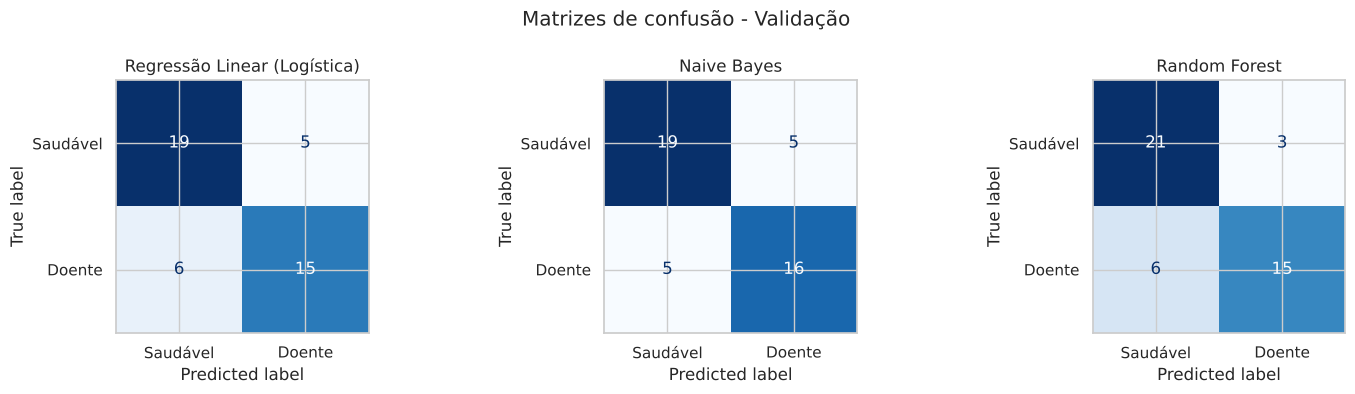

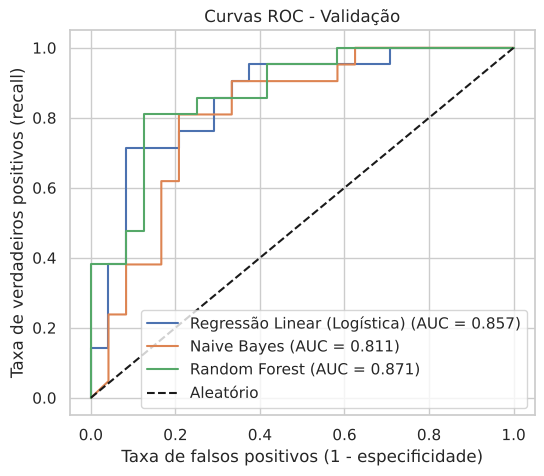

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (nome, p) in zip(axes, previsoes.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_val, p['y_pred']),
                           display_labels=['Saudável', 'Doente']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(nome)
plt.suptitle('Matrizes de confusão - Validação')
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 5))
for nome, p in previsoes.items():
    fpr, tpr, _ = roc_curve(y_val, p['y_proba'])
    plt.plot(fpr, tpr, label=f"{nome} (AUC = {roc_auc_score(y_val, p['y_proba']):.3f})")
plt.plot([0, 1], [0, 1], 'k--', label='Aleatório')
plt.xlabel('Taxa de falsos positivos (1 - especificidade)')
plt.ylabel('Taxa de verdadeiros positivos (recall)')
plt.title('Curvas ROC - Validação')
plt.legend()
plt.show()

### 5.3 Definição do melhor modelo
Critério: maior **ROC AUC** na validação (mede a qualidade da probabilidade em qualquer limiar,
importante para triagem). Em caso de empate, desempata pelo **recall** (menos doentes não detectados).

In [31]:
ranking = res_val.sort_values(['ROC AUC', 'Recall'], ascending=False)
MELHOR = ranking.index[0]
melhor_modelo = modelos[MELHOR]
print('Ranking (validação):')
print(ranking[['ROC AUC', 'Recall', 'Accuracy']].round(4))
print(f'\nMelhor modelo: {MELHOR}')

Ranking (validação):
                              ROC AUC  Recall  Accuracy
Random Forest                  0.8710  0.7143    0.8000
Regressão Linear (Logística)   0.8571  0.7143    0.7556
Naive Bayes                    0.8105  0.7619    0.7778

Melhor modelo: Random Forest


### 5.4 Avaliação final no conjunto de teste
O conjunto de teste não participou do treino nem da escolha do modelo, então representa o desempenho
esperado com pacientes novos.

In [32]:
res_teste = {}
for nome, modelo in modelos.items():
    y_pred  = modelo.predict(X_teste)
    y_proba = modelo.predict_proba(X_teste)[:, 1]
    res_teste[nome] = calcular_metricas(y_teste, y_pred, y_proba)
res_teste = pd.DataFrame(res_teste).T
res_teste.round(4)

,Accuracy,Precision,Recall,Especificidade,ROC AUC
Regressão Linear (Logística),0.8478,0.9375,0.7143,0.96,0.9219
Naive Bayes,0.8261,0.8824,0.7143,0.92,0.8648
Random Forest,0.8261,0.9333,0.6667,0.96,0.9048


Validação                                   \
                              Accuracy Precision  Recall Especificidade   
Regressão Linear (Logística)    0.7556    0.7500  0.7143         0.7917   
Naive Bayes                     0.7778    0.7619  0.7619         0.7917   
Random Forest                   0.8000    0.8333  0.7143         0.8750   

                                        Teste                    \
                             ROC AUC Accuracy Precision  Recall   
Regressão Linear (Logística)  0.8571   0.8478    0.9375  0.7143   
Naive Bayes                   0.8105   0.8261    0.8824  0.7143   
Random Forest                 0.8710   0.8261    0.9333  0.6667   

                                                     
                             Especificidade ROC AUC  
Regressão Linear (Logística)           0.96  0.9219  
Naive Bayes                            0.92  0.8648  
Random Forest                          0.96  0.9048

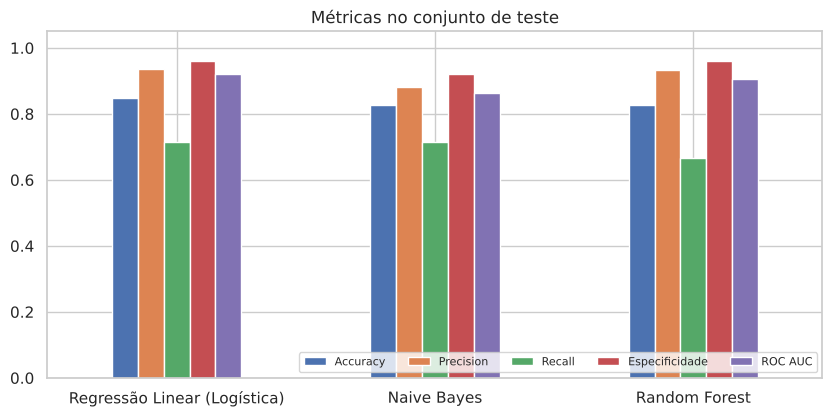

Métricas finais do melhor modelo (Random Forest) no teste:
Accuracy          0.8261
Precision         0.9333
Recall            0.6667
Especificidade    0.9600
ROC AUC           0.9048
Name: Random Forest, dtype: float64


In [33]:
comparacao = pd.concat({'Validação': res_val, 'Teste': res_teste}, axis=1).round(4)
display(comparacao)

ax = res_teste.plot(kind='bar', figsize=(10, 4.5), rot=0)
ax.set_ylim(0, 1.05)
ax.set_title('Métricas no conjunto de teste')
ax.legend(loc='lower right', ncol=5, fontsize=8)
plt.show()

print(f'Métricas finais do melhor modelo ({MELHOR}) no teste:')
print(res_teste.loc[MELHOR].round(4))

### 5.5 Avaliação e testes para novos dados
Simulamos a chegada de **novos pacientes** na triagem. Os dados passam exatamente pelo mesmo
pipeline do treinamento (one-hot → mesmas colunas → NumPy → mesmo `scaler`) e o melhor modelo
devolve a classe (`predict`) e a probabilidade de doença (`predict_proba`).

In [34]:
def preparar_novos_dados(novos_df):
    """Aplica nos novos pacientes o mesmo pré-processamento usado no treino."""
    X_novo = pd.get_dummies(novos_df, columns=CATEGORICAS, dtype=int)
    X_novo = X_novo.reindex(columns=COLUNAS_MODELO, fill_value=0)   # mesmas colunas e ordem
    return scaler.transform(X_novo.to_numpy(dtype=float))

novos_pacientes = pd.DataFrame([
    # perfil de baixo risco: jovem, sem angina, boa frequência máxima
    {'age': 35, 'sex': 0, 'cp': 2, 'trestbps': 118, 'chol': 190, 'fbs': 0, 'restecg': 1,
     'thalach': 182, 'exang': 0, 'oldpeak': 0.0, 'slope': 2, 'ca': 0, 'thal': 2},
    # perfil de alto risco: idoso, angina no exercício, depressão ST alta, vasos obstruídos
    {'age': 66, 'sex': 1, 'cp': 0, 'trestbps': 160, 'chol': 300, 'fbs': 1, 'restecg': 0,
     'thalach': 110, 'exang': 1, 'oldpeak': 3.2, 'slope': 1, 'ca': 2, 'thal': 3},
    # perfil intermediário
    {'age': 54, 'sex': 1, 'cp': 1, 'trestbps': 135, 'chol': 245, 'fbs': 0, 'restecg': 1,
     'thalach': 150, 'exang': 0, 'oldpeak': 1.0, 'slope': 1, 'ca': 0, 'thal': 2},
], index=['Paciente A', 'Paciente B', 'Paciente C'])

X_novos = preparar_novos_dados(novos_pacientes)

resultado = novos_pacientes.copy()
for nome, modelo in modelos.items():
    resultado[f'{nome} - prob. doença'] = modelo.predict_proba(X_novos)[:, 1].round(3)
resultado['Melhor modelo - predict'] = melhor_modelo.predict(X_novos)
resultado['Diagnóstico sugerido'] = np.where(resultado['Melhor modelo - predict'] == 1,
                                              'ALTO RISCO - encaminhar para exames',
                                              'Baixo risco')
resultado

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,Regressão Linear (Logística) - prob. doença,Naive Bayes - prob. doença,Random Forest - prob. doença,Melhor modelo - predict,Diagnóstico sugerido
Paciente A,35,0,2,118,190,0,1,182,0,0.0,2,0,2,0.001,0.001,0.012,0,Baixo risco
Paciente B,66,1,0,160,300,1,0,110,1,3.2,1,2,3,1.000,1.000,0.984,1,ALTO RISCO - encaminhar para exames
Paciente C,54,1,1,135,245,0,1,150,0,1.0,1,0,2,0.353,0.037,0.286,0,Baixo risco


In [35]:
# Teste de sanidade: pacientes reais do conjunto de teste passando pela mesma função de previsão
amostra_idx = X_teste_df.index[:5]
amostra = df.loc[amostra_idx.map(lambda i: indices[i])].drop(columns=[TARGET])
pred_amostra = melhor_modelo.predict(preparar_novos_dados(amostra))
print('Real    :', y_teste[:5])
print('Previsto:', pred_amostra)
print('Igual à previsão feita no X_teste?',
      np.array_equal(pred_amostra, melhor_modelo.predict(X_teste[:5])))

Real    : [0 1 0 1 1]
Previsto: [0 1 0 1 0]
Igual à previsão feita no X_teste? True


---
## Conclusão
* A EDA mostrou que, no arquivo do Kaggle, a coluna `target` está **invertida** (1 = perfil saudável);
  ela foi corrigida para seguir a definição do projeto (1 = com doença).
* A EDA também mostrou que o dataset do Kaggle tem **cerca de 70% de linhas duplicadas**; removê-las foi
  essencial para obter métricas honestas (com elas, os modelos chegam perto de 100% por "decorar" pacientes
  repetidos).
* Os dados foram divididos em 70/15/15 com estratificação, balanceados apenas no treino e normalizados
  com o `StandardScaler` ajustado somente no treino, evitando vazamento de dados.
* Os três modelos foram comparados pelas métricas accuracy, precision, recall, especificidade e ROC AUC.
  O **Random Forest** teve o maior ROC AUC na validação (0,871) e foi escolhido como melhor modelo. No
  teste ele obteve ROC AUC de 0,905, accuracy de 0,826, precision de 0,933, recall de 0,667 e
  especificidade de 0,960.
* A **Regressão Logística** ficou muito próxima e foi até um pouco melhor no teste (ROC AUC de 0,922).
  Com poucos dados, os dois modelos são praticamente equivalentes; o **Naive Bayes** foi o mais fraco,
  por assumir independência entre as variáveis.
* O recall de cerca de 0,67 significa que um em cada três doentes do teste não foi detectado com o
  limiar padrão de 0,5. Para uma triagem, onde o falso negativo é o erro mais grave, o hospital poderia
  usar um limiar menor sobre o `predict_proba` (ex.: 0,3), aumentando o recall em troca de mais
  encaminhamentos para exames.
* Como o conjunto limpo tem cerca de 300 pacientes, os conjuntos de validação e teste são pequenos
  (~45 pacientes cada) e as métricas podem variar alguns pontos percentuais conforme a semente aleatória.
* O modelo serve como **ferramenta de apoio à triagem**: pacientes com alta probabilidade de doença são
  priorizados para exames complementares, mas a decisão final continua sendo do médico.